## Phase 1 : Data Understanding & Exploratory Data Analysis

In [8]:
import pandas as pd
all_sheets = pd.read_excel(r"C:\Users\Alish\OneDrive\Desktop\Mawdoo3 Internship\customer-intelligence-ml\Data\raw_data.xlsx"
, sheet_name=None)

# Combine all the DataFrames from the dictionary into one single DataFrame
df = pd.concat(all_sheets.values(), ignore_index=True)
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [9]:
# Convert the Invoice column to strings to safely search for the letter 'C'
df['Invoice_Str'] = df['Invoice'].astype(str)

# Filter for rows where the invoice starts with 'C'
cancellations = df[df['Invoice_Str'].str.startswith('C', na=False)]

print(f"Total cancelled transactions: {len(cancellations)}")
cancellations.head(20)

Total cancelled transactions: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Invoice_Str
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,C489449
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,C489449
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,C489449
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,C489449
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,C489449
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,C489449
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,C489449
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,C489449
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,C489449
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,C489459


In [37]:
df_clean = df.dropna(subset=['Customer ID']).copy()
df_clean = df_clean[~df_clean['Invoice'].astype(str).str.startswith('C')]
print(f"original rows {len(df)}")
print(f"cleaned rows {len(df_clean)}")
df_clean.describe()
#df_clean.info()
#no_id.head(10)

original rows 1067371
cleaned rows 805620


,Quantity,InvoiceDate,Price,Customer ID
count,805620.000000,805620,805620.000000,805620.000000
mean,13.307665,2011-01-02 10:26:35.704327,3.206279,15331.856250
min,1.000000,2009-12-01 07:45:00,0.000000,12346.000000
25%,2.000000,2010-07-07 12:08:00,1.250000,13982.000000
50%,5.000000,2010-12-03 15:10:00,1.950000,15271.000000
75%,12.000000,2011-07-28 13:28:00,3.750000,16805.000000
max,80995.000000,2011-12-09 12:50:00,10953.500000,18287.000000
std,144.306739,NaN,29.197901,1696.768395


In [48]:
duplicate_rows = df_clean.duplicated().sum()
print(duplicate_rows)
df_clean = df_clean.drop_duplicates()
df_clean.info()
df_clean['Total Price'] = df_clean['Quantity'] * df_clean['Price']
top_10_customers = df_clean.groupby('Customer ID')['Total Price'].sum().nlargest(10)
print(top_10_customers)
df_clean.head(10)


0
<class 'pandas.DataFrame'>
Index: 779495 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      779495 non-null  object        
 1   StockCode    779495 non-null  object        
 2   Description  779495 non-null  object        
 3   Quantity     779495 non-null  int64         
 4   InvoiceDate  779495 non-null  datetime64[us]
 5   Price        779495 non-null  float64       
 6   Customer ID  779495 non-null  float64       
 7   Country      779495 non-null  str           
 8   Invoice_Str  779495 non-null  str           
 9   Total Price  779495 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(2)
memory usage: 79.9+ MB
Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Invoice_Str,Total Price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,489434,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,489434,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,489434,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,489434,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,489434,30.0
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,489434,39.6
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,489434,30.0
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,489434,59.5
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom,489435,30.6
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom,489435,45.0


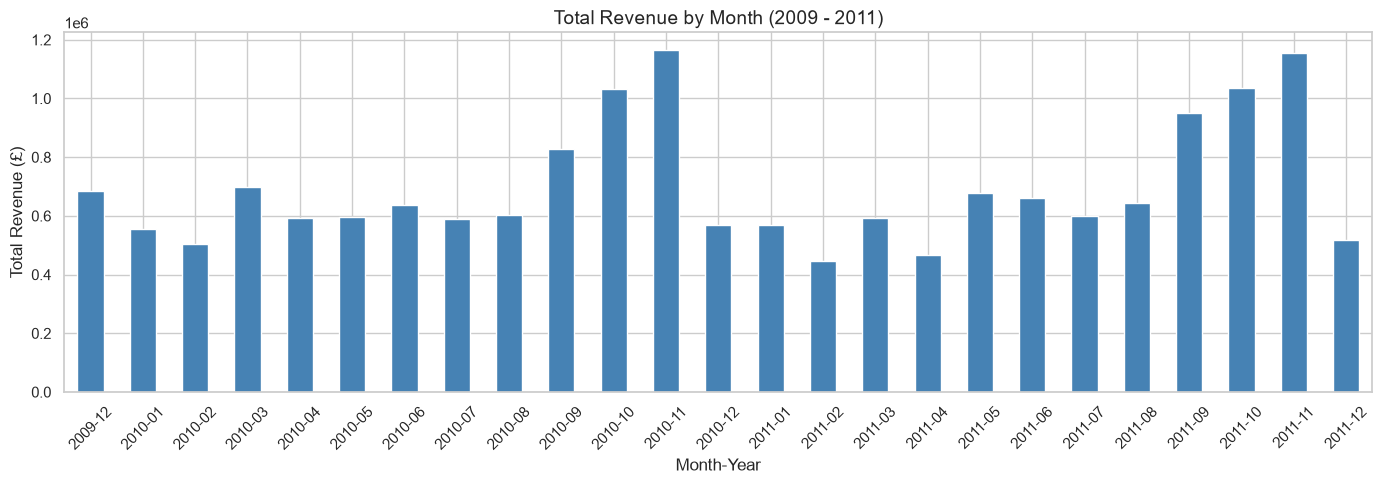

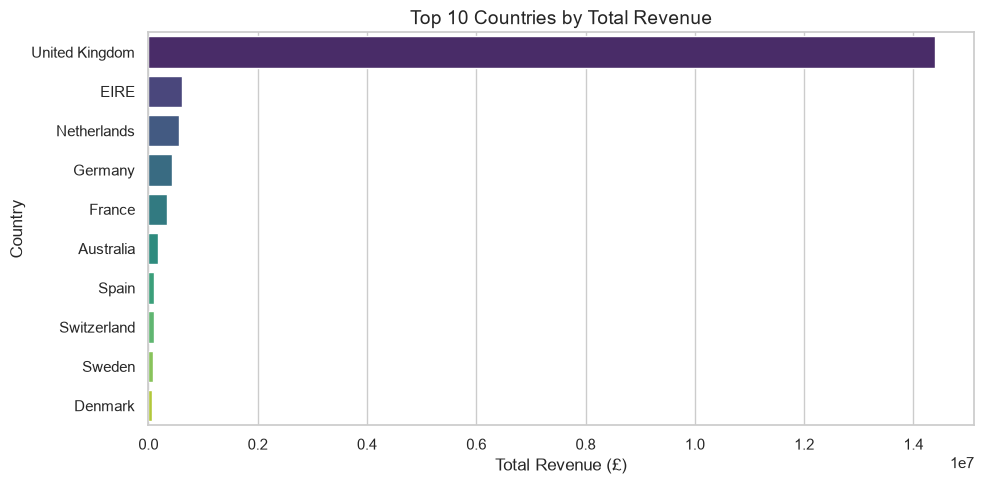

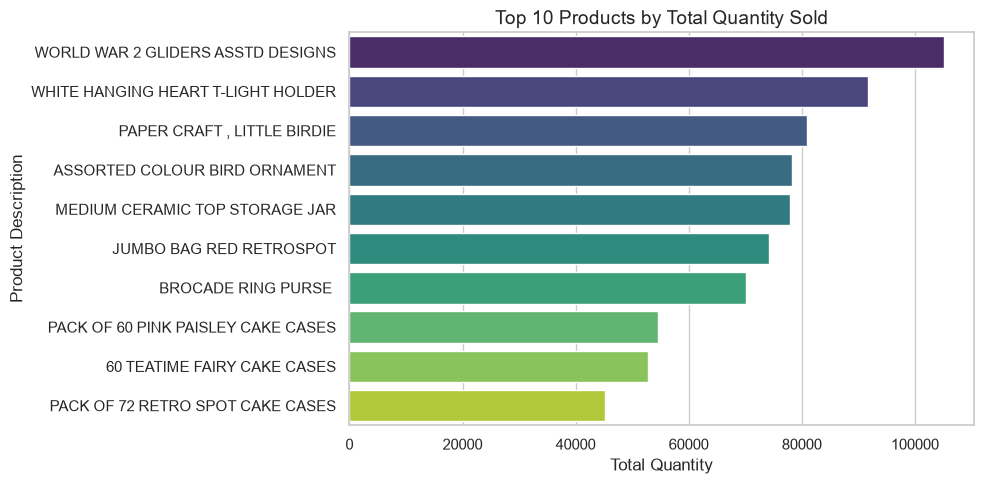

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
monthly_sales = df_clean.groupby('YearMonth')['Total Price'].sum()

plt.figure(figsize=(14, 5))
monthly_sales.plot(kind='bar', color='steelblue')
plt.title('Total Revenue by Month (2009 - 2011)', fontsize=14)
plt.xlabel('Month-Year', fontsize=12)
plt.ylabel('Total Revenue (£)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

country_sales = df_clean.groupby('Country')['Total Price'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
# Using seaborn for a clean horizontal bar chart
sns.barplot(x=country_sales.values, y=country_sales.index, hue=country_sales.index, legend=False, palette='viridis')
plt.title('Top 10 Countries by Total Revenue', fontsize=14)
plt.xlabel('Total Revenue (£)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.tight_layout()
plt.show()

top_products = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
# Using seaborn for a clean horizontal bar chart
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, legend=False, palette='viridis')
plt.title('Top 10 Products by Total Quantity Sold', fontsize=14)
plt.xlabel('Total Quantity', fontsize=12)
plt.ylabel('Product Description', fontsize=12)
plt.tight_layout()
plt.show()

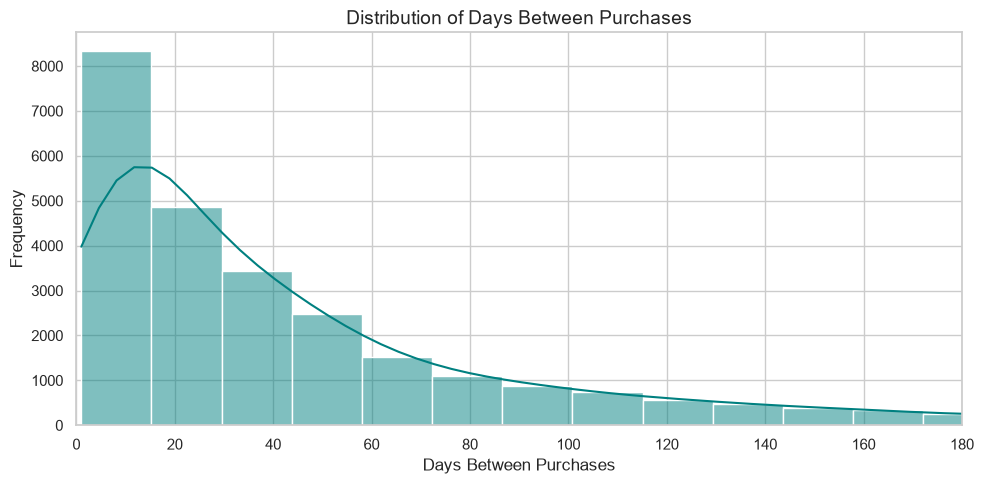

count    27231.000000
mean        59.013918
std         78.267838
min          1.000000
25%         13.000000
50%         31.000000
75%         70.000000
max        714.000000
Name: Days_Between, dtype: float64

In [58]:
customer_dates = df_clean.groupby(['Customer ID', df_clean['InvoiceDate'].dt.date]).size().reset_index()
customer_dates.rename(columns={'InvoiceDate': 'Purchase_Date'}, inplace=True)
customer_dates['Purchase_Date'] = pd.to_datetime(customer_dates['Purchase_Date'])

customer_dates = customer_dates.sort_values(['Customer ID', 'Purchase_Date'])
customer_dates['Days_Between'] = customer_dates.groupby('Customer ID')['Purchase_Date'].diff().dt.days

plt.figure(figsize=(10, 5))
sns.histplot(customer_dates['Days_Between'].dropna(), bins=50, color='teal', kde=True)
plt.title('Distribution of Days Between Purchases', fontsize=14)
plt.xlabel('Days Between Purchases', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xlim(0, 180) # Limit to one year for better visibility
plt.tight_layout()
plt.show()

customer_dates['Days_Between'].describe()

In [61]:
import datetime as dt

reference_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
rfm = df_clean.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,  # Recency
    'Invoice': 'nunique',                                      # Frequency (unique orders)
    'Total Price': 'sum'                                       # Monetary
}).reset_index()

rfm.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']
print(rfm.describe())
rfm.head()

        Customer ID      Recency    Frequency       Monetary
count   5881.000000  5881.000000  5881.000000    5881.000000
mean   15314.674205   201.457745     6.287196    2954.396237
std     1715.429759   209.474135    13.012879   14437.322635
min    12346.000000     1.000000     1.000000       0.000000
25%    13833.000000    26.000000     1.000000     341.900000
50%    15313.000000    96.000000     3.000000     865.600000
75%    16797.000000   380.000000     7.000000    2247.720000
max    18287.000000   739.000000   398.000000  580987.040000


,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40


## Phase 2 : Data Preprocessing & Feature Engineering 

In [62]:
import pandas as pd
import datetime as dt

def build_customer_intelligence_dataset(df, target_window_days=30):
    """
    Phase 2 Reusable Preprocessing Pipeline.
    Cleans data, engineers features, and prevents data leakage via temporal splitting.
    """
    # 1. Clean Data (Requirements 1, 2, 3)
    df_clean = df.dropna(subset=['Customer ID']).copy()
    df_clean = df_clean[~df_clean['Invoice'].astype(str).str.startswith('C')]
    df_clean = df_clean.drop_duplicates()
    df_clean['Total_Price'] = df_clean['Quantity'] * df_clean['Price']
    
    # 2. Temporal Split to prevent Data Leakage (Requirement 7)
    max_date = df_clean['InvoiceDate'].max()
    cutoff_date = max_date - pd.Timedelta(days=target_window_days)
    
    feature_window = df_clean[df_clean['InvoiceDate'] <= cutoff_date]
    target_window = df_clean[df_clean['InvoiceDate'] > cutoff_date]
    buyers_in_target = target_window['Customer ID'].unique()
    
    ref_date = cutoff_date + pd.Timedelta(days=1)
    
    # 3. Aggregate Features (Requirements 4 & 5)
    customer_features = feature_window.groupby('Customer ID').agg({
        'InvoiceDate': lambda x: (ref_date - x.max()).days,  # Recency
        'Invoice': 'nunique',                                # Total Historical Orders (Frequency)
        'Total_Price': 'sum',                                # Monetary Value
        'Quantity': 'sum',                                   # Total Purchased Quantity
        'StockCode': 'nunique'                               # Number of Unique Products Purchased
    }).reset_index()
    
    # Rename columns to match the project requirements exactly
    customer_features.columns = [
        'Customer ID', 'Recency', 'Frequency', 'Monetary_Value', 
        'Total_Purchased_Quantity', 'Unique_Products_Purchased'
    ]
    
    # Calculate Average Order Value
    customer_features['Average_Order_Value'] = customer_features['Monetary_Value'] / customer_features['Frequency']
    
    # 4. Create the Target Variable for Machine Learning
    customer_features['Target_Next_30_Days'] = customer_features['Customer ID'].isin(buyers_in_target).astype(int)
    
    return customer_features

# Execute the reusable pipeline on your original combined dataframe 'df'
ml_data = build_customer_intelligence_dataset(df)

# Check the final output
ml_data.head()

,Customer ID,Recency,Frequency,Monetary_Value,Total_Purchased_Quantity,Unique_Products_Purchased,Average_Order_Value,Target_Next_30_Days
0,12346.0,296,12,77556.46,74285,27,6463.038333,0
1,12347.0,10,7,4696.71,2775,123,670.958571,1
2,12348.0,45,5,2019.40,2714,25,403.880000,0
3,12349.0,378,3,2671.14,993,90,890.380000,1
4,12350.0,280,1,334.40,197,17,334.400000,0


## Phase 3 : Supervised Machine Learning: Purchase Predictions

              precision    recall  f1-score   support

           0       0.82      0.82      0.82       854
           1       0.47      0.49      0.48       290

    accuracy                           0.73      1144
   macro avg       0.65      0.65      0.65      1144
weighted avg       0.73      0.73      0.73      1144



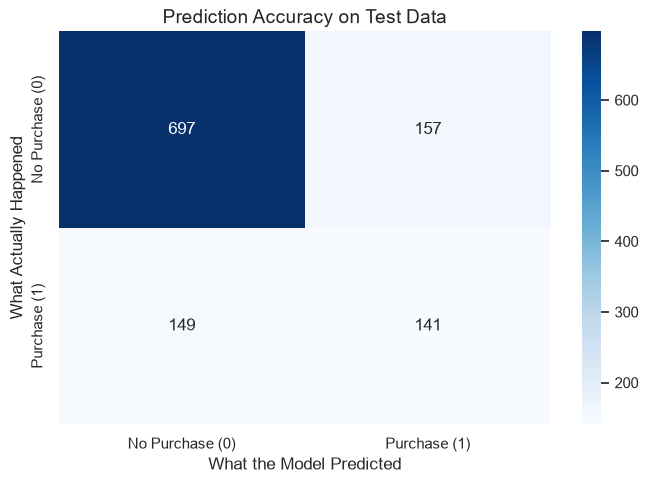

In [65]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'Recency', 'Frequency', 'Monetary_Value', 'Total_Purchased_Quantity', 'Unique_Products_Purchased', 'Average_Order_Value'
]

x = ml_data[features]
y = ml_data['Target_Next_30_Days']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

RFC_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
RFC_model.fit(X_train, y_train)

RFC_predictions = RFC_model.predict(X_test)
print(classification_report(y_test, RFC_predictions))

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, RFC_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Purchase (0)', 'Purchase (1)'], 
            yticklabels=['No Purchase (0)', 'Purchase (1)'])
plt.title('Prediction Accuracy on Test Data', fontsize=14)
plt.xlabel('What the Model Predicted', fontsize=12)
plt.ylabel('What Actually Happened', fontsize=12)
plt.tight_layout()
plt.show()